# Customer Churn Prediction — live classroom demo

Run the cells in order, or choose **Restart Kernel → Run All**. This notebook needs only the Telco CSV and standard Python ML libraries; it does not load the app model or modify project artifacts.

Install `requirements-dev.txt` into the selected environment first, or run `%pip install pandas numpy scikit-learn matplotlib` in a setup cell. If needed, set `CSV_PATH` below to the full CSV path.

## 1. Load and inspect the data

The target is `Churn`: Yes = 1, No = 0. Customer ID is an identifier, not a model feature.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CSV_PATH = None
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

if CSV_PATH is None:
    roots = [Path.cwd(), Path.cwd().parent]
    if "__file__" in globals():
        roots.insert(0, Path(__file__).resolve().parents[1])
    candidates = [root / "data/raw/telco_churn.csv" for root in roots]
    candidates.append(Path.cwd() / "telco_churn.csv")
    CSV_PATH = next((path for path in candidates if path.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError("Set CSV_PATH to the full path of data/raw/telco_churn.csv, then rerun.")

raw = pd.read_csv(CSV_PATH, dtype={"customerID": "string"}, keep_default_na=False)
print(f"Dataset: {len(raw):,} rows, {len(raw.columns)} columns")
display(raw.head())

Dataset: 7,043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean and explore

The original dataset has 11 blank total charges, all for zero-tenure customers; treat those as zero. Validate training identifiers and target labels. The EDA describes the whole fictional dataset, including the eventual holdout.

Blank TotalCharges replaced with zero: 11
Churn rate: 26.5%


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76,2279.73
std,0.37,24.56,30.09,2266.79
min,0.00,0.00,18.25,0.00
25%,0.00,9.00,35.50,398.55
50%,0.00,29.00,70.35,1394.55
75%,0.00,55.00,89.85,3786.60
max,1.00,72.00,118.75,8684.80


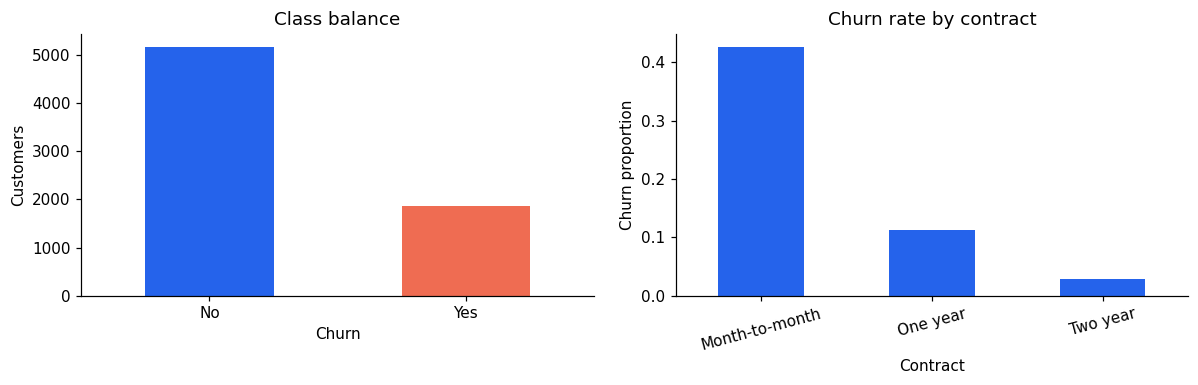

In [2]:
df = raw.copy()
identifiers = df["customerID"].str.strip()
if identifiers.eq("").any() or identifiers.duplicated().any():
    raise ValueError("The training CSV must have non-empty, unique customer IDs.")
if not df["Churn"].isin(["Yes", "No"]).all():
    raise ValueError("Churn must contain only Yes and No.")
blank_total = df["TotalCharges"].astype(str).str.strip().eq("")
if (blank_total & df["tenure"].ne(0)).any():
    raise ValueError("Blank TotalCharges is allowed only for zero-tenure customers.")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].mask(blank_total, "0"), errors="raise")
print(f"Blank TotalCharges replaced with zero: {blank_total.sum()}")
print(f"Churn rate: {df['Churn'].eq('Yes').mean():.1%}")
display(df.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df["Churn"].value_counts().reindex(["No", "Yes"]).plot.bar(
    ax=axes[0], color=["#2563eb", "#ef6c52"], rot=0, title="Class balance")
axes[0].set_ylabel("Customers")
df.assign(churn=df["Churn"].eq("Yes")).groupby("Contract")["churn"].mean().plot.bar(
    ax=axes[1], color="#2563eb", rot=15, title="Churn rate by contract")
axes[1].set_ylabel("Churn proportion")
plt.tight_layout()
plt.show()

## 3. Split first; learn preprocessing inside the pipeline

Use a stratified 80/20 split. Imputation, scaling and one-hot encoding are fitted separately in each training fold. Logistic regression is preselected for this teaching demo; three-fold CV keeps execution light. The full project compares more models using five folds.

In [3]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
assert set(identifiers.loc[X_train.index]).isdisjoint(identifiers.loc[X_test.index])
numeric = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical = [column for column in X.columns if column not in numeric]
preprocessing = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
])
model = Pipeline([
    ("preprocessing", preprocessing),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_validate(model, X_train, y_train, cv=cv,
                           scoring={"AP": "average_precision", "ROC_AUC": "roc_auc"})
display(pd.DataFrame({
    "Training CV metric": ["Average precision", "ROC-AUC"],
    "Mean": [cv_scores["test_AP"].mean(), cv_scores["test_ROC_AUC"].mean()],
    "Std": [cv_scores["test_AP"].std(), cv_scores["test_ROC_AUC"].std()],
}).round(4))
print(f"Train: {len(X_train):,}; holdout: {len(X_test):,}. Imputation, scaling and encoding fit within each fold.")

,Training CV metric,Mean,Std
0,Average precision,0.6604,0.0109
1,ROC-AUC,0.8458,0.0076


Train: 5,634; holdout: 1,409. Imputation, scaling and encoding fit within each fold.


## 4. Choose the operating threshold on training data

Out-of-fold training probabilities determine a cut-off for approximately 30% outreach. Do not optimise the threshold on holdout labels. Fit on all training rows and compare with a baseline that predicts no churn. AP and ROC-AUC describe ranking; precision, recall and F1 depend on the cut-off.

In [4]:
oof_probability = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold = float(np.quantile(oof_probability, 0.70))
model.fit(X_train, y_train)
probability = model.predict_proba(X_test)[:, 1]
prediction = (probability >= threshold).astype(int)
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
baseline_prediction = baseline.predict(X_test)
results = []
for name, scores, labels in [
    ("Majority baseline", baseline_probability, baseline_prediction),
    ("Logistic regression", probability, prediction),
]:
    results.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, scores),
                    "Average precision": average_precision_score(y_test, scores),
                    "Precision": precision_score(y_test, labels, zero_division=0),
                    "Recall": recall_score(y_test, labels, zero_division=0),
                    "F1": f1_score(y_test, labels, zero_division=0),
                    "Accuracy": accuracy_score(y_test, labels)})
display(pd.DataFrame(results).set_index("Model").round(4))
print(f"Training-only threshold: {threshold:.4f}; holdout flagged: {prediction.mean():.1%}")
print("The 30% outreach target is approximate, not a hard capacity limit.")

,ROC-AUC,Average precision,Precision,Recall,F1,Accuracy
Model,,,,,,
Majority baseline,0.5000,0.2654,0.0000,0.0000,0.0000,0.7346
Logistic regression,0.8421,0.6343,0.5695,0.6791,0.6195,0.7786


Training-only threshold: 0.3933; holdout flagged: 31.7%
The 30% outreach target is approximate, not a hard capacity limit.


## 5. Evaluate and explain

The confusion matrix shows false positives and missed churners. The PR curve is useful for an imbalanced target. Calibration compares predicted risks with observed frequencies. Permutation importance measures model reliance, not causation; small or negative values may be noise.

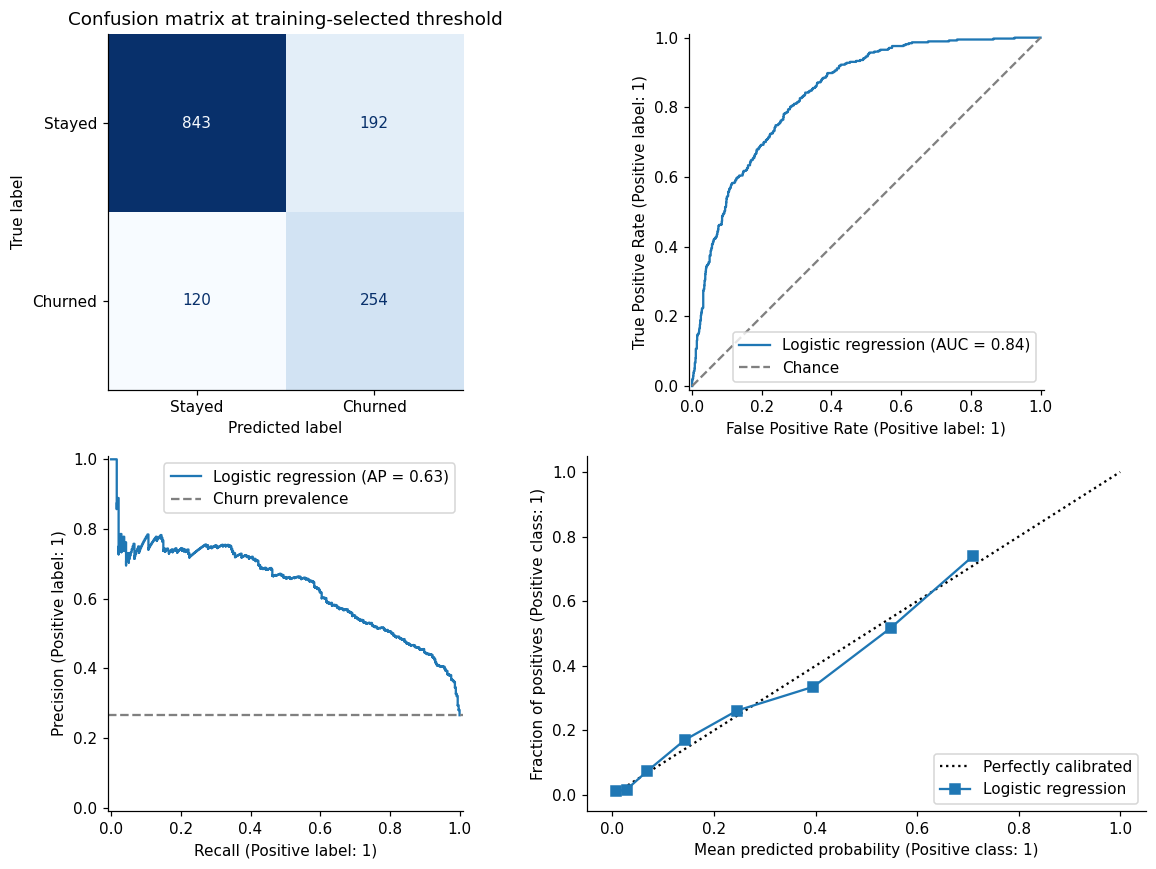

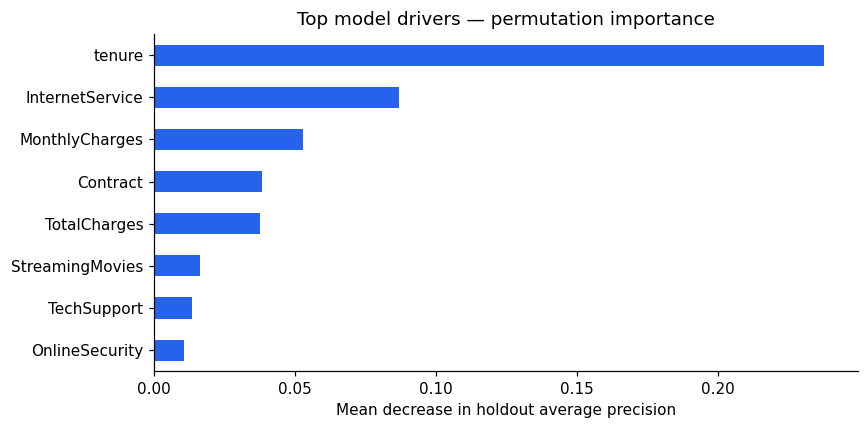

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=["Stayed", "Churned"],
                                        ax=axes[0, 0], cmap="Blues", colorbar=False)
axes[0, 0].set_title("Confusion matrix at training-selected threshold")
RocCurveDisplay.from_predictions(y_test, probability, ax=axes[0, 1], name="Logistic regression")
axes[0, 1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes[0, 1].legend()
PrecisionRecallDisplay.from_predictions(y_test, probability, ax=axes[1, 0], name="Logistic regression")
axes[1, 0].axhline(y_test.mean(), linestyle="--", color="gray", label="Churn prevalence")
axes[1, 0].legend()
CalibrationDisplay.from_predictions(y_test, probability, n_bins=8, strategy="quantile",
                                    ax=axes[1, 1], name="Logistic regression")
plt.tight_layout()
plt.show()

importance = permutation_importance(model, X_test, y_test, scoring="average_precision",
                                   n_repeats=3, random_state=RANDOM_STATE)
ranking = pd.Series(importance.importances_mean, index=X.columns).nlargest(8).sort_values()
ranking.plot.barh(figsize=(8, 4), color="#2563eb", title="Top model drivers — permutation importance")
plt.xlabel("Mean decrease in holdout average precision")
plt.tight_layout()
plt.show()

## 6. Score example customers

These examples come from the holdout and their labels are shown only for comparison. You can edit `customer` below and rerun its prediction. This notebook accepts the original Telco CSV; the app adds stricter production-style input checks. No model or predictions are saved.

In [6]:
sample = X_test.iloc[:5].copy()
sample_scores = model.predict_proba(sample)[:, 1]
demo_predictions = pd.DataFrame({
    "customerID": df.loc[sample.index, "customerID"].to_numpy(),
    "churn_probability": sample_scores,
    "flag_for_outreach": sample_scores >= threshold,
    "actual_churn": y_test.loc[sample.index].to_numpy(),
})
display(demo_predictions.round(4))
print("Live prediction example:")
customer = X_test.iloc[[0]].copy()
display(customer)
print(f"Predicted churn risk: {model.predict_proba(customer)[0, 1]:.1%}")
print("Demo only: fictional data, previously inspected holdout, no causal or production claims.")

,customerID,churn_probability,flag_for_outreach,actual_churn
0,4376-KFVRS,0.0459,False,0
1,2754-SDJRD,0.6837,True,0
2,9917-KWRBE,0.0589,False,0
3,0365-GXEZS,0.4018,True,0
4,9385-NXKDA,0.0214,False,0


Live prediction example:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


Predicted churn risk: 4.6%
Demo only: fictional data, previously inspected holdout, no causal or production claims.


## What to say in the presentation

**Why not just accuracy?** Around 73.5% do not churn, so a do-nothing classifier already looks accurate.

**Why a pipeline?** Learned preprocessing must not see validation or test rows.

**Why tune a threshold?** Ranking risk and deciding whom to contact are different decisions. The approximate outreach target reflects an assumed capacity, not measured profit.

**What are the limitations?** Fictional data, random rather than temporal splitting, a holdout already inspected during development, and no independent validation or fairness review. Risk does not prove that an offer prevents churn.

**Why do these scores differ from the README?** This teaching run uses three-fold CV with one preselected model. The shipped model used the full five-fold comparison and feature ablation.